# Praktikum Sub-CPMK-2 &mdash; Perbaikan Citra pada Domain Spasial

**Pengolahan Citra Digital (IF2514505)** &nbsp;|&nbsp; Semester 5 &nbsp;|&nbsp; 1 SKS Praktikum &nbsp;|&nbsp; Durasi sasaran 135 menit (rentang 120&ndash;150)

**Program Studi Informatika &mdash; Institut Teknologi Kalimantan**

---

| | |
|---|---|
| **Nama** | ................................................ |
| **NIM** | ................................................ |
| **Kelas / Kelompok** | ................................................ |
| **Tanggal praktikum** | ................................................ |

---

### Capaian yang diukur
**Sub-CPMK-2**: Mahasiswa mampu menerapkan teknik perbaikan citra pada domain spasial termasuk histogram equalization.

### Rujukan utama
Gonzalez, R.C. dan Woods, R.E. (2018) *Digital Image Processing*, edisi ke-4, Bab 3 (§3.1&ndash;3.6). Nomor persamaan pada notebook ini mengikuti buku tersebut.

### Petunjuk pengerjaan
1. Jalankan sel secara berurutan. Sel bertanda `# TODO` wajib Anda lengkapi sendiri.
2. Setiap blok **Analisis** diisi kalimat Anda sendiri dan **wajib memuat angka** dari keluaran Anda.
3. Citra uji dibangkitkan di dalam notebook (benih acak tetap) &mdash; **tidak perlu mengunggah berkas apa pun**.
4. Bagian bertanda **[Pengayaan]** boleh dilewati bila waktu tidak cukup; jalur inti selesai dalam &plusmn;120 menit.
5. Kumpulkan notebook dalam keadaan **sudah dijalankan penuh** dengan nama `PraktikumPCD_SubCPMK2_NIM_Nama.ipynb`.

| Bagian | Isi | Menit |
|---|---|---|
| 0 | Persiapan dan citra uji | 10 |
| 1 | Transformasi intensitas melalui tabel penelusuran (§3.2) | 25 |
| 2 | Histogram equalization, spesifikasi, dan CLAHE (§3.3) | 35 |
| 3 | Penapisan spasial: korelasi, penghalusan, penajaman (§3.4&ndash;3.6) | 40 |
| 4 | Studi kasus mini: citra perairan berkabut | 15 |
| 5 | Pemeriksaan akhir dan pengumpulan | 10 |


## Bagian 0 &mdash; Persiapan (10 menit)
Sel berikut memuat pustaka, fungsi bantu, dan pembangkit citra uji. **Jalankan tanpa diubah.**

NumPy 2.4.6 | OpenCV 5.0.0
redup     (256, 256) uint8 min 41 maks 114
dokumen   (240, 320) uint8 min 3 maks 251
bersih    (256, 256) uint8 min 8 maks 251
berderau  (256, 256) uint8 min 0 maks 255
perairan  (240, 360) uint8 min 89 maks 203


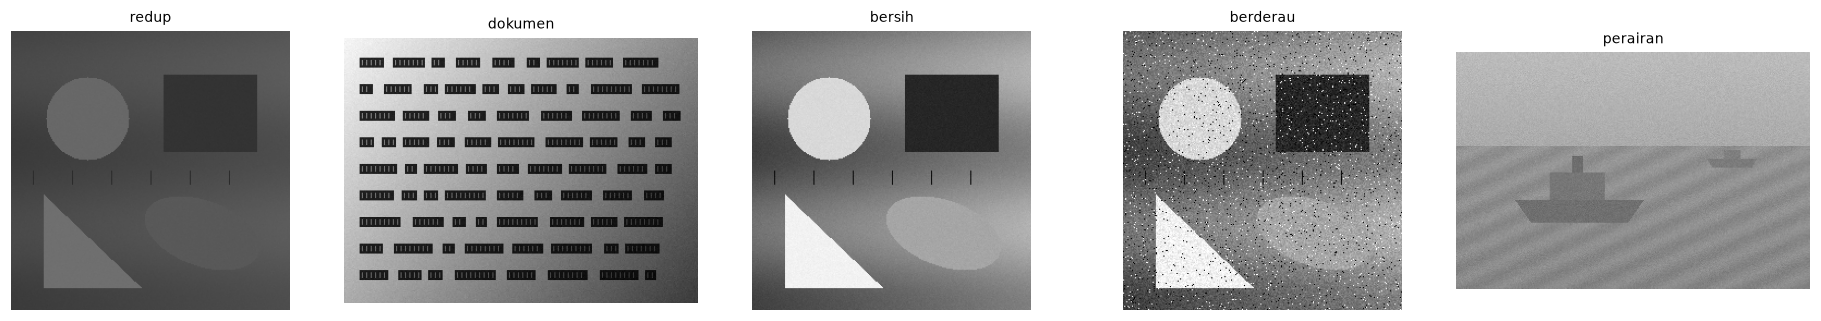

In [1]:
# Sel persiapan — jalankan tanpa diubah
import numpy as np
import cv2
import matplotlib.pyplot as plt
import time

plt.rcParams['figure.dpi'] = 110
print('NumPy', np.__version__, '| OpenCV', cv2.__version__)

"""Pembangkit citra uji sintetis (benih acak tetap, hanya NumPy).

Hanya memakai NumPy (tanpa fungsi gambar OpenCV) agar citra identik di versi
OpenCV mana pun. Seluruh citra bebas persoalan lisensi dan reprodusibel.
"""
import numpy as np

BENIH = 2026


def _grid(h, w):
    return np.mgrid[0:h, 0:w].astype(np.float64)


def _adegan(rng, h=256, w=256):
    """Adegan dasar: gradasi, lingkaran, persegi, elips, segitiga, garis halus (float 0..1)."""
    yy, xx = _grid(h, w)
    img = 0.35 + 0.25 * (xx / w) + 0.10 * np.sin(yy / 23.0)
    img[(xx - 70) ** 2 + (yy - 80) ** 2 <= 38 ** 2] = 0.85                    # lingkaran terang
    img[(yy >= 40) & (yy <= 110) & (xx >= 140) & (xx <= 225)] = 0.15          # persegi gelap
    u, v = xx - 175, yy - 185
    t = np.deg2rad(20)
    ue, ve = u * np.cos(t) + v * np.sin(t), -u * np.sin(t) + v * np.cos(t)
    img[(ue / 55) ** 2 + (ve / 30) ** 2 <= 1] = 0.65                          # elips
    img[(yy >= 150) & (yy <= 235) & (xx >= 30) & (xx <= 30 + (yy - 150) * 1.05)] = 0.95  # segitiga
    for i in range(6):                                                          # rincian halus
        img[128:141, 20 + 36 * i] = 0.05
    img += rng.normal(0, 0.01, img.shape)
    return np.clip(img, 0, 1)


def citra_redup(rng):
    """Kontras rendah: intensitas termampatkan ke rentang sempit (kira-kira 40..115)."""
    return np.clip(40 + 75 * _adegan(rng), 0, 255).round().astype(np.uint8)


def dokumen_tak_merata(rng, h=240, w=320):
    """'Baris teks' gelap di atas kertas terang, pencahayaan dari kiri atas."""
    img = np.full((h, w), 0.92)
    for b in range(9):                                    # 9 baris teks
        y0 = 18 + 24 * b
        x = 14
        while x < w - 20:
            pj = int(rng.integers(10, 38))                # panjang 'kata'
            if x + pj > w - 14:
                break
            img[y0:y0 + 9, x:x + pj] = 0.14
            img[y0 + 2:y0 + 7, x + 2:x + pj - 2:4] = 0.55  # celah antarhuruf
            x += pj + int(rng.integers(6, 12))
    yy, xx = _grid(h, w)
    cahaya = 1.05 - 0.80 * ((xx / w) * 0.6 + (yy / h) * 0.4)
    img = img * cahaya + rng.normal(0, 0.012, (h, w))
    return np.clip(255 * img, 0, 255).round().astype(np.uint8)


def citra_bersih(rng):
    """Kebenaran dasar untuk uji penapis (rentang penuh)."""
    return np.clip(255 * _adegan(rng), 0, 255).round().astype(np.uint8)


def beri_derau(img, rng, sigma=12.0, p_sp=0.04):
    """Derau Gaussian (sigma) ditambah derau garam-merica (proporsi p_sp)."""
    g = img.astype(np.float64) + rng.normal(0, sigma, img.shape)
    u = rng.random(img.shape)
    g[u < p_sp / 2] = 0
    g[(u >= p_sp / 2) & (u < p_sp)] = 255
    return np.clip(g, 0, 255).round().astype(np.uint8)


def perairan_berkabut(rng, h=240, w=360):
    """Langit, laut bergelombang, dua kapal, kabut (kontras rendah), derau sensor."""
    yy, xx = _grid(h, w)
    cak = 95
    langit = 0.78 - 0.15 * (yy / cak)
    laut = 0.42 + 0.06 * np.sin(xx / 9.0 + yy / 4.0) - 0.10 * ((yy - cak) / (h - cak))
    img = np.where(yy < cak, langit, laut)
    # kapal besar: lambung trapesium + bangunan + cerobong
    lambung = (yy >= 150) & (yy <= 172) & (xx >= 60 + (yy - 150) * 0.7) & (xx <= 190 - (yy - 150) * 0.7)
    img[lambung] = 0.12
    img[(yy >= 122) & (yy < 150) & (xx >= 95) & (xx <= 150)] = 0.18
    img[(yy >= 105) & (yy < 122) & (xx >= 118) & (xx <= 128)] = 0.10
    # kapal kecil di kejauhan
    img[(yy >= 108) & (yy <= 116) & (xx >= 255 + (yy - 108) * 0.6) & (xx <= 305 - (yy - 108) * 0.6)] = 0.22
    img[(yy >= 99) & (yy < 108) & (xx >= 272) & (xx <= 288)] = 0.25
    kabut = 0.55
    img = (1 - kabut) * img + kabut * 0.70
    img += rng.normal(0, 0.018, img.shape)
    return np.clip(255 * img, 0, 255).round().astype(np.uint8)


def masker_perairan(h=240, w=360):
    """Masker kebenaran dasar: (kapal, laut). Laut = di bawah cakrawala, di luar kapal, dengan jarak aman."""
    yy, xx = _grid(h, w)
    kapal = np.zeros((h, w), bool)
    kapal |= (yy >= 150) & (yy <= 172) & (xx >= 60 + (yy - 150) * 0.7) & (xx <= 190 - (yy - 150) * 0.7)
    kapal |= (yy >= 122) & (yy < 150) & (xx >= 95) & (xx <= 150)
    kapal |= (yy >= 105) & (yy < 122) & (xx >= 118) & (xx <= 128)
    kapal |= (yy >= 108) & (yy <= 116) & (xx >= 255 + (yy - 108) * 0.6) & (xx <= 305 - (yy - 108) * 0.6)
    kapal |= (yy >= 99) & (yy < 108) & (xx >= 272) & (xx <= 288)
    sekitar = np.zeros_like(kapal)
    sekitar[95:185, 45:205] = True
    sekitar[92:125, 245:315] = True
    laut = (yy >= 100) & ~sekitar
    return kapal, laut


def bangkitkan_semua():
    rng = np.random.default_rng(BENIH)
    redup = citra_redup(rng)
    dok = dokumen_tak_merata(rng)
    bersih = citra_bersih(rng)
    berderau = beri_derau(bersih, rng)
    laut = perairan_berkabut(rng)
    return {"redup": redup, "dokumen": dok, "bersih": bersih, "berderau": berderau, "perairan": laut}

def tampil(daftar, judul=None, kolom=None, tinggi=3.0):
    n = len(daftar); kolom = kolom or n; baris = int(np.ceil(n / kolom))
    fig, ax = plt.subplots(baris, kolom, figsize=(3.4 * kolom, tinggi * baris))
    ax = np.atleast_1d(ax).ravel()
    for a in ax: a.axis('off')
    for a, im, t in zip(ax, daftar, judul or [''] * n):
        a.imshow(im, cmap='gray', vmin=0, vmax=255); a.set_title(t, fontsize=9)
    plt.tight_layout(); plt.show()

def gambar_hist(ax, im, judul=''):
    h = np.bincount(im.ravel(), minlength=256)
    ax.bar(np.arange(256), h, width=1.0, color='#16324F')
    a2 = ax.twinx(); a2.plot(np.cumsum(h) / h.sum(), color='#C2680E', lw=1.5, ls='--'); a2.set_ylim(0, 1.05)
    ax.set_title(judul, fontsize=9); ax.set_xlim(-2, 257)

def entropi(im):
    h = np.bincount(im.ravel(), minlength=256).astype(float); p = h[h > 0] / h.sum()
    return float(-(p * np.log2(p)).sum())

def psnr(acuan, uji):
    mse = np.mean((acuan.astype(float) - uji.astype(float)) ** 2)
    return float('inf') if mse == 0 else float(10 * np.log10(255 ** 2 / mse))

def ringkas(nama, im):
    print(f'{nama:24s} rerata {im.mean():7.2f}  std {im.std():6.2f}  min {im.min():3d}  maks {im.max():3d}'
          f'  aras {len(np.unique(im)):3d}  entropi {entropi(im):.4f}')

C = bangkitkan_semua()
redup, dok, bersih, berderau, perairan = C['redup'], C['dokumen'], C['bersih'], C['berderau'], C['perairan']
kabur = cv2.GaussianBlur(bersih, (9, 9), 1.5)   # masukan untuk Bagian 3.3
for k, v in C.items(): print(f'{k:9s}', v.shape, v.dtype, 'min', v.min(), 'maks', v.max())
tampil([redup, dok, bersih, berderau, perairan], list(C.keys()))

## Bagian 1 &mdash; Transformasi intensitas melalui tabel penelusuran (25 menit)

Transformasi intensitas $s = T(r)$ (Gonzalez Eq. 3-2) hanya bergantung pada nilai piksel itu sendiri. Karena masukan 8-bit hanya memiliki 256 kemungkinan nilai, $T$ cukup dihitung **sekali** untuk 256 aras lalu disimpan sebagai *lookup table* (LUT); penerapannya cukup dengan pengindeksan `lut[img]`.

Rumus yang dipakai: negatif $s = L-1-r$ (Eq. 3-3), logaritmik $s = c\log(1+r)$ (Eq. 3-4), dan pangkat $s = c\,r^{\gamma}$ (Eq. 3-5) yang di sini ditulis dalam bentuk ternormalisasi $s = 255\,(r/255)^{\gamma}$.

**Aturan pembulatan modul ini:** $\lfloor x + 0{,}5 \rfloor$ (setengah dibulatkan ke atas). Jangan memakai `np.round`, yang membulatkan 2,5 menjadi 2.

In [2]:
# TODO 1.1 — Lengkapi fungsi pembuat LUT. Semua keluaran harus uint8 dalam rentang 0..255.
r = np.arange(256, dtype=np.float64)

def bulat(x):
    return np.floor(x + 0.5)

def lut_negatif():
    return np.clip(bulat(255 - r), 0, 255).astype(np.uint8)

def lut_log():
    c = 255 / np.log(256)          # agar r = 255 dipetakan ke 255
    return np.clip(bulat(c * np.log(1 + r)), 0, 255).astype(np.uint8)

def lut_gamma(g):
    return np.clip(bulat(255 * (r / 255.0) ** g), 0, 255).astype(np.uint8)

# Uji cepat terhadap hitungan tangan (harus True semua)
print(lut_negatif()[0] == 255, lut_gamma(0.5)[64] == 128, lut_gamma(2.0)[64] == 16, lut_log()[10] == 110)


True True True True


asli                     rerata   78.54  std  15.27  min  41  maks 114  aras  62  entropi 5.3350
gamma 0,5                rerata  140.85  std  13.77  min 102  maks 170  aras  56  entropi 5.1646
gamma 2,0                rerata   25.07  std   9.65  min   7  maks  51  aras  38  entropi 4.6069
min-maks                 rerata  131.16  std  53.44  min   0  maks 255  aras  62  entropi 5.3350
sepotong                 rerata  119.12  std  65.64  min  14  maks 237  aras  44  entropi 5.0112


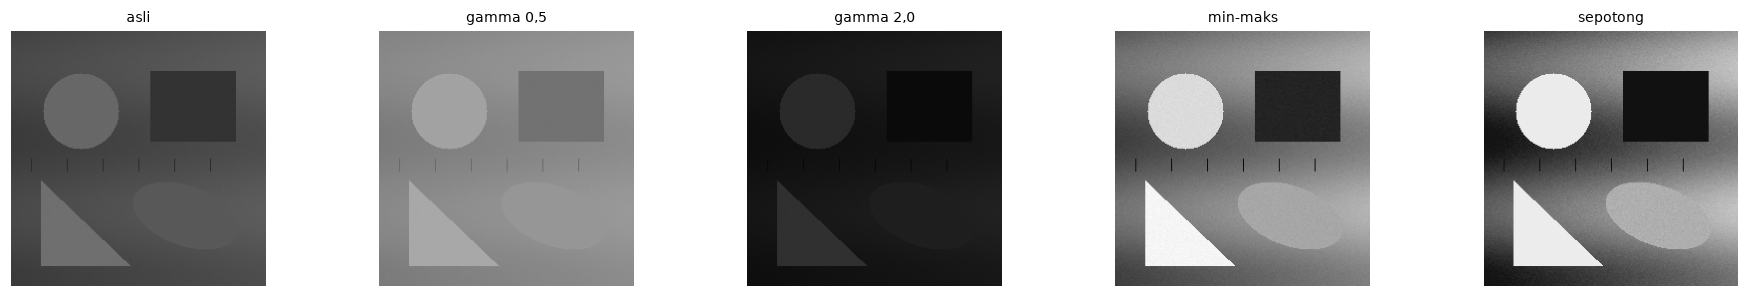

In [3]:
# TODO 1.2 — Peregangan kontras.
# (a) Min–maks: petakan [min, maks] citra ke [0, 255].
# (b) Sepotong-sepotong melalui titik (r1, s1) dan (r2, s2) — Gonzalez Fig. 3.10. Gunakan np.interp.
def lut_minmaks(im):
    lo, hi = float(im.min()), float(im.max())
    if hi == lo:
        return np.zeros(256, dtype=np.uint8)
    return np.clip(bulat((r - lo) / (hi - lo) * 255), 0, 255).astype(np.uint8)

def lut_sepotong(r1, s1, r2, s2):
    return np.clip(bulat(np.interp(r, [0, r1, r2, 255], [0, s1, s2, 255])), 0, 255).astype(np.uint8)

# Terapkan pada citra redup, lalu cetak ringkasan untuk: asli, gamma 0,5, gamma 2,0, min–maks,
# dan sepotong-sepotong (r1, s1, r2, s2) = (60, 20, 100, 235). Tampilkan kelima citra.
varian = {
    'asli': redup,
    'gamma 0,5': lut_gamma(0.5)[redup],
    'gamma 2,0': lut_gamma(2.0)[redup],
    'min-maks': lut_minmaks(redup)[redup],
    'sepotong': lut_sepotong(60, 20, 100, 235)[redup],
}
for nama, im in varian.items():
    ringkas(nama, im)
tampil(list(varian.values()), list(varian.keys()), kolom=5, tinggi=2.8)


In [4]:
# TODO 1.3 — Buktikan keunggulan LUT: bandingkan waktu gamma lewat LUT vs perhitungan pangkat langsung
# pada citra 2000×2000 (np.tile). Laporkan nisbah kecepatannya.
besar = np.tile(bersih, (8, 8))[:2000, :2000]
lut = lut_gamma(0.5)

t0 = time.perf_counter(); hasil_lut = lut[besar]; t1 = time.perf_counter()
t2 = time.perf_counter(); hasil_langsung = np.clip(bulat(255 * (besar / 255.0) ** 0.5), 0, 255).astype(np.uint8); t3 = time.perf_counter()

print(f'LUT       : {t1 - t0:.6f} s')
print(f'Langsung  : {t3 - t2:.6f} s')
print(f'Nisbah    : {(t3 - t2) / (t1 - t0):.1f}x lebih cepat dengan LUT')
print('Hasil identik:', np.array_equal(hasil_lut, hasil_langsung))


LUT       : 0.008144 s
Langsung  : 0.036251 s
Nisbah    : 4.5x lebih cepat dengan LUT
Hasil identik: True


**Analisis 1.** (a) Pada citra `redup`, gamma 0,5 menaikkan rerata tetapi simpangan bakunya justru turun. Jelaskan dengan bentuk kurva gamma pada rentang masukan citra ini (lihat nilai min&ndash;maks Anda). (b) Peregangan min&ndash;maks menaikkan simpangan baku berlipat, tetapi jumlah aras dan entropi tidak berubah. Mengapa? (c) Apa yang terjadi pada jumlah aras bila rentang keluaran lebih sempit daripada rentang masukan?

*Jawaban Anda:*

**(a)** Pada `redup` rentang masukannya sempit, min 41 dan maks 114 (rerata 78,54; std 15,27). Dengan γ=0,5 keluaran menjadi min 102, maks 170, rerata naik ke 140,85, tetapi std turun ke 13,77. Kurva γ=0,5 cekung sehingga menaikkan nilai rendah, namun kemiringan lokalnya ds/dr = 0,5·(255/r)^0,5 turun dari ≈1,25 di r=41 menjadi ≈0,75 di r=114. Karena sebagian besar piksel berada di sekitar rerata 78,5 (kemiringan ≈0,90 < 1), jarak antar-aras justru termampatkan sehingga std turun.

**(b)** Peregangan min–maks adalah transformasi affine s = 255(r−41)/(114−41). Transformasi affine hanya menggeser dan menskalakan semua aras, tidak menggabungkan dua aras berbeda. Karena itu jumlah aras tetap 62 dan entropi tetap 5,3350, sedangkan std naik dari 15,27 ke 53,44 (faktor ≈255/73 = 3,49).

**(c)** Bila rentang keluaran lebih sempit daripada rentang masukan, kemiringan rata-rata < 1 sehingga beberapa aras masukan yang berdekatan jatuh ke aras keluaran yang sama setelah pembulatan; jumlah aras turun. Pada percobaan ini `sepotong` menghasilkan 44 aras dan γ=0,5 menghasilkan 56 aras, dibandingkan 62 aras pada citra asli.


## Bagian 2 &mdash; Histogram equalization, spesifikasi, dan CLAHE (35 menit)

Bentuk diskret histogram equalization (Gonzalez Eq. 3-15):

$$s_k = T(r_k) = (L-1)\sum_{j=0}^{k} p_r(r_j), \qquad p_r(r_j) = \frac{n_j}{MN}$$

In [5]:
# TODO 2.1 — Implementasikan Eq. 3-15 sebagai LUT, lalu uji pada contoh 8 aras dari modul kuliah.
def lut_he(im, L=256):
    h = np.bincount(im.ravel(), minlength=L).astype(np.float64)
    p = h / h.sum()
    cdf = np.cumsum(p)
    return np.clip(bulat((L - 1) * cdf), 0, L - 1).astype(np.uint8)

# Contoh kuliah: citra 8x8, 3-bit (L = 8), banyaknya piksel per aras 0..7
n_contoh = [10, 20, 14, 8, 5, 4, 2, 1]
contoh = np.repeat(np.arange(8), n_contoh).reshape(8, 8).astype(np.uint8)
print('LUT HE contoh 8 aras:', lut_he(contoh, L=8)[:8])


LUT HE contoh 8 aras: [1 3 5 6 6 7 7 7]


In [6]:
# TODO 2.2 — Bandingkan implementasi Anda dengan cv2.equalizeHist pada `redup` dan `berderau`.
# Cetak: banyaknya piksel berbeda, dan selisih mutlak maksimum.
for nama, im in [('redup', redup), ('berderau', berderau)]:
    hasil = lut_he(im)[im]
    pustaka = cv2.equalizeHist(im)
    beda = np.count_nonzero(hasil != pustaka)
    selisih = np.abs(hasil.astype(int) - pustaka.astype(int)).max()
    print(f'{nama:9s} piksel berbeda {beda:6d}  selisih mutlak maksimum {selisih}')


redup     piksel berbeda      0  selisih mutlak maksimum 0
berderau  piksel berbeda  59713  selisih mutlak maksimum 6


**Analisis 2.1.** Pada salah satu citra, hasil Anda identik dengan pustaka; pada citra lain berbeda pada puluhan ribu piksel. Periksa histogram `berderau` pada aras 0, lalu rumuskan dugaan tentang rumus yang dipakai `cv2.equalizeHist`. **Uji dugaan Anda** dengan menulis varian `lut_he_cdfmin` di sel berikut hingga selisihnya nol pada kedua citra. Apakah ini berarti implementasi Eq. 3-15 Anda salah?

*Jawaban Anda:*

Pada `redup` hasil saya sama persis dengan `cv2.equalizeHist` (0 piksel berbeda), sedangkan pada `berderau` berbeda pada 59.713 piksel dengan selisih maksimum 6 aras. Histogram `berderau` memiliki lonjakan besar di aras 0, yaitu 1.372 piksel (2,09% dari 65.536 piksel) akibat derau garam.

Dugaan saya: OpenCV tidak memakai CDF penuh seperti Eq. 3-15, tetapi menormalkan dengan CDF minimum, yaitu s = (L−1)(cdf(r) − cdf_min)/(MN − cdf_min), sehingga aras terendah yang muncul dipetakan tepat ke 0. Setelah `lut_he_cdfmin` diuji, selisihnya menjadi 0 piksel pada `redup` maupun `berderau`. Ini tidak berarti implementasi Eq. 3-15 salah: Eq. 3-15 memang benar sebagai rumus HE baku, sedangkan OpenCV memakai varian cdf_min agar keluaran selalu mulai dari 0 ketika ada massa piksel di aras 0.


In [7]:
# TODO 2.3 — Tulis lut_he_cdfmin(im) dan buktikan selisihnya nol terhadap cv2.equalizeHist pada kedua citra.
def lut_he_cdfmin(im):
    h = np.bincount(im.ravel(), minlength=256).astype(np.float64)
    total = h.sum()
    nz = np.nonzero(h)[0]
    cdf_min = h[nz[0]]
    lut = np.zeros(256, dtype=np.uint8)
    jumlah = 0.0
    for i in range(nz[0], 256):
        jumlah += h[i]
        lut[i] = int(np.clip(bulat(255.0 * (jumlah - cdf_min) / (total - cdf_min)), 0, 255))
    return lut

for nama, im in [('redup', redup), ('berderau', berderau)]:
    hasil = lut_he_cdfmin(im)[im]
    pustaka = cv2.equalizeHist(im)
    beda = np.count_nonzero(hasil != pustaka)
    selisih = np.abs(hasil.astype(int) - pustaka.astype(int)).max()
    print(f'{nama:9s} piksel berbeda {beda:6d}  selisih mutlak maksimum {selisih}')


redup     piksel berbeda      0  selisih mutlak maksimum 0
berderau  piksel berbeda      0  selisih mutlak maksimum 0


### 2.4 Spesifikasi histogram (*histogram matching*)

Langkah diskret menurut Gonzalez (Eq. 3-20 s.d. 3-23): (1) hitung $s_k$ dengan Eq. 3-15; (2) hitung $G(z_q) = (L-1)\sum_{i=0}^{q} p_z(z_i)$ dari histogram sasaran dan bulatkan; (3) untuk setiap $s_k$ cari $z_q$ dengan $G(z_q)$ **terdekat**; bila ada lebih dari satu, **pilih yang terkecil**.

In [8]:
# TODO 2.4 — Implementasikan spesifikasi histogram, lalu uji pada contoh kuliah dengan sasaran
# pz = [0, 2, 6, 10, 14, 16, 10, 6] / 64. Pemetaan r -> z yang benar: [2 3 5 6 6 7 7 7].
def lut_spesifikasi(im, pz, L=256):
    s_lut = lut_he(im, L)
    pz = np.asarray(pz, dtype=np.float64)
    pz = pz / pz.sum()
    G = bulat((L - 1) * np.cumsum(pz))
    z = np.arange(L)
    lut = np.zeros(L, dtype=np.uint8)
    for k in range(L):
        lut[k] = int(np.argmin(np.abs(G - s_lut[k])))
    return lut

pz = np.array([0, 2, 6, 10, 14, 16, 10, 6]) / 64
print('Pemetaan r -> z:', lut_spesifikasi(contoh, pz, L=8)[:8])


Pemetaan r -> z: [2 3 5 6 6 7 7 7]


Spesifikasi Gaussian : rerata 129.90  std 39.61
HE biasa             : rerata 131.07  std 73.64
Sasaran              : rerata 128.00  std 40.00


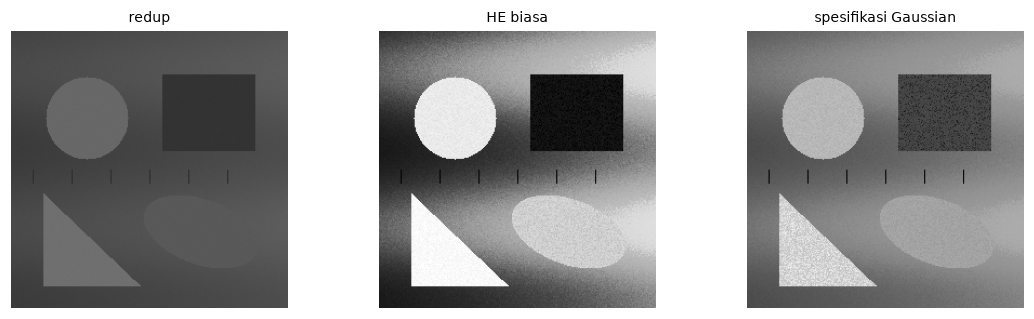

In [9]:
# [Pengayaan] TODO 2.5 — Spesifikasikan `redup` ke histogram sasaran berbentuk Gaussian (rerata 128, sb 40).
# Bandingkan rerata dan std hasilnya dengan HE biasa. Mana yang lebih dekat ke sasaran?
xs = np.arange(256)
pz_gauss = np.exp(-((xs - 128.0) ** 2) / (2 * 40.0 ** 2))
pz_gauss /= pz_gauss.sum()

hasil_spec = lut_spesifikasi(redup, pz_gauss)[redup]
hasil_he = lut_he(redup)[redup]
print(f'Spesifikasi Gaussian : rerata {hasil_spec.mean():.2f}  std {hasil_spec.std():.2f}')
print(f'HE biasa             : rerata {hasil_he.mean():.2f}  std {hasil_he.std():.2f}')
print('Sasaran              : rerata 128.00  std 40.00')
tampil([redup, hasil_he, hasil_spec], ['redup', 'HE biasa', 'spesifikasi Gaussian'], kolom=3)


### 2.6 Ekualisasi lokal: CLAHE
Gonzalez §3.3 membahas ekualisasi lokal dengan jendela bergeser. CLAHE (Zuiderveld, 1994) adalah varian praktis: ekualisasi per ubin, histogram dipotong pada `clipLimit`, lalu antar-ubin diinterpolasi bilinear. CLAHE **tidak dibahas rinci** di Gonzalez; perlakukan sebagai pengayaan.

asli         TL  179.90  BR   75.87  std  62.36  entropi 7.5480
HE global    TL  201.54  BR   57.00  std  73.52  entropi 7.4016
CLAHE 1      TL  180.27  BR   88.91  std  62.27  entropi 7.4919
CLAHE 2      TL  172.17  BR   97.14  std  59.12  entropi 7.4025
CLAHE 4      TL  164.09  BR  106.02  std  57.69  entropi 7.3512
CLAHE 8      TL  151.13  BR  119.66  std  60.03  entropi 7.4624

Kekasaran latar (std Laplacian pada kertas kosong):
asli         rerata  146.82  std   8.32  kekasaran  13.83
HE global    rerata  147.73  std  14.15  kekasaran  23.69
CLAHE 1      rerata  155.92  std  12.92  kekasaran  23.65
CLAHE 2      rerata  162.31  std  10.77  kekasaran  35.10
CLAHE 4      rerata  163.60  std  17.55  kekasaran  57.15
CLAHE 8      rerata  166.79  std  28.70  kekasaran  96.02


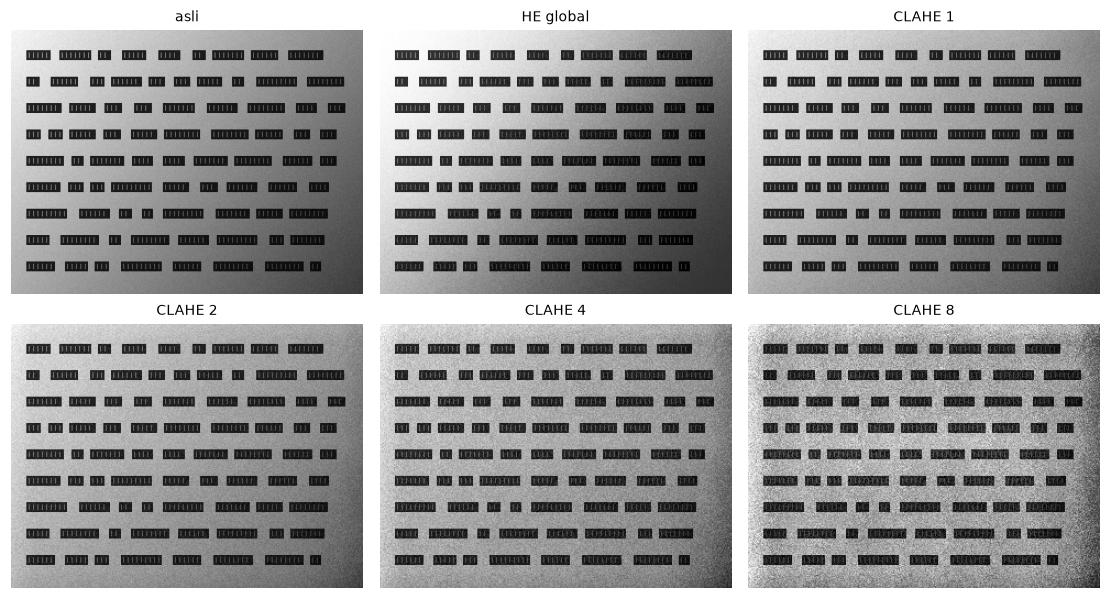

In [10]:
# TODO 2.6 — Pada `dok`, bandingkan asli, HE global, dan CLAHE untuk clipLimit 1, 2, 4, 8 (ubin 8×8).
# Untuk setiap hasil cetak: rerata daerah kiri-atas dok[:80, :100], rerata daerah kanan-bawah dok[160:, 220:],
# simpangan baku, dan entropi. Tampilkan citranya.
def metrik_dok(nama, im):
    print(f'{nama:12s} TL {im[:80, :100].mean():7.2f}  BR {im[160:, 220:].mean():7.2f}  std {im.std():6.2f}  entropi {entropi(im):.4f}')

hasil_clahe = [dok, cv2.equalizeHist(dok)]
judul = ['asli', 'HE global']
metrik_dok('asli', dok)
metrik_dok('HE global', hasil_clahe[1])
for cl in [1, 2, 4, 8]:
    im = cv2.createCLAHE(clipLimit=cl, tileGridSize=(8, 8)).apply(dok)
    metrik_dok(f'CLAHE {cl}', im)
    hasil_clahe.append(im)
    judul.append(f'CLAHE {cl}')

print('\nKekasaran latar (std Laplacian pada kertas kosong):')
reg = (slice(0, 14), slice(240, 315))
for nama, im in zip(judul, hasil_clahe):
    latar = im[reg].astype(np.float64)
    print(f'{nama:12s} rerata {latar.mean():7.2f}  std {latar.std():6.2f}  kekasaran {cv2.Laplacian(latar, cv2.CV_64F).std():6.2f}')

tampil(hasil_clahe, judul, kolom=3, tinggi=2.8)


**Analisis 2.2.** (a) Dengan angka daerah kanan-bawah, tunjukkan mengapa HE global gagal pada citra berpencahayaan tak merata. (b) Tetapkan satu clipLimit untuk `dok` dan justifikasi dengan angka, bukan kesan visual. Ingat: entropi yang lebih tinggi tidak otomatis lebih baik bila yang naik adalah derau latar. (c) Sebutkan satu jenis citra yang **tidak boleh** diekualisasi bila nilai pikselnya akan diukur, dan mengapa.

*Jawaban Anda:*

**(a)** Pada `dok`, HE global menaikkan rerata kiri-atas dari 179,90 menjadi 201,54 tetapi justru menurunkan rerata kanan-bawah dari 75,87 menjadi 57,00. CDF global didominasi kertas terang, sehingga daerah terang dipetakan makin terang (mendekati 255) dan daerah gelap makin gelap; selisih kiri-atas–kanan-bawah malah membesar dari 104,03 menjadi 144,54. Jadi HE global tidak meratakan pencahayaan tak merata.

**(b)** Saya memilih **clipLimit = 2**. Dengan clip 2, selisih rerata kiri-atas–kanan-bawah turun dari 104,03 (asli) menjadi 75,03, rerata kanan-bawah naik ke 97,14, dan entropi 7,4025 (tidak lebih tinggi dari asli 7,5480). Harga yang dibayar: kekasaran latar (std Laplacian pada daerah kertas kosong) naik dari 13,83 menjadi 35,10. Pada clip 4 dan 8 perataan lebih kuat (selisih 58,07 dan 31,47) tetapi kekasaran latar meledak menjadi 57,15 dan 96,02, tanda derau latar ikut diperkuat. Clip 1 hanya menurunkan selisih ke 91,36 dengan kekasaran 23,65, sehingga clip 2 adalah kompromi terbaik antara perataan pencahayaan dan penguatan derau latar.

**(c)** Citra medis seperti CT/MRI (atau citra ilmiah lain) yang nilai pikselnya akan diukur secara kuantitatif tidak boleh diekualisasi, karena HE/CLAHE mengubah nilai intensitas secara nonlinier dan lokal sehingga nilai HU atau intensitas jaringan tidak lagi bermakna dan dapat menimbulkan struktur semu.


## Bagian 3 &mdash; Penapisan spasial (40 menit)

Korelasi (Gonzalez Eq. 3-31): $g(x,y) = \sum_{s=-a}^{a}\sum_{t=-b}^{b} w(s,t)\,f(x+s,\,y+t)$. Konvolusi (Eq. 3-35) sama, tetapi kernel diputar 180&deg; lebih dahulu. Catatan: `cv2.filter2D` melaksanakan **korelasi**.

In [11]:
# TODO 3.1 — Tulis korelasi 2D untuk kernel 3×3 dengan padding replikasi tepi (np.pad mode='edge').
# Gunakan penjumlahan 9 citra tergeser (tanpa perulangan per piksel). Validasi terhadap
# cv2.filter2D(..., borderType=cv2.BORDER_REPLICATE) pada `bersih` (float64): selisih maks harus < 1e-9.
def korelasi3(f, w):
    f = np.asarray(f, dtype=np.float64)
    w = np.asarray(w, dtype=np.float64)
    h, wd = f.shape
    fp = np.pad(f, 1, mode='edge')
    out = np.zeros_like(f)
    for i in range(3):
        for j in range(3):
            out += w[i, j] * fp[i:i + h, j:j + wd]
    return out

w_tak_setangkup = np.array([[1, 0, 0], [0, 0, 0], [0, 0, 2]], float)
hasil = korelasi3(bersih, w_tak_setangkup)
acuan = cv2.filter2D(bersih.astype(np.float64), -1, w_tak_setangkup, borderType=cv2.BORDER_REPLICATE)
print('Selisih maksimum terhadap cv2.filter2D:', np.abs(hasil - acuan).max())
print('Lolos < 1e-9:', np.abs(hasil - acuan).max() < 1e-9)

# Lalu hitung konvolusi = korelasi dengan np.flip(w) dan tunjukkan bedanya pada jendela contoh kuliah:
jendela = np.array([[10, 20, 30], [40, 50, 60], [70, 80, 90]], float)   # jawaban: korelasi 190, konvolusi 110
print('Korelasi :', korelasi3(jendela, w_tak_setangkup)[1, 1])
print('Konvolusi:', korelasi3(jendela, np.flip(w_tak_setangkup))[1, 1])


Selisih maksimum terhadap cv2.filter2D: 0.0
Lolos < 1e-9: True
Korelasi : 190.0
Konvolusi: 110.0


In [12]:
# TODO 3.2 — Bandingkan penapis penghalus pada `berderau` (derau Gaussian + garam-merica) dengan PSNR terhadap `bersih`.
# Kandidat: rerata 3×3 dan 5×5; Gaussian 5×5 σ=0,8 dan 9×9 σ=1,5 (ukuran ≈ ⌈6σ⌉ ganjil, Gonzalez §3.5);
# median 3×3 dan 5×5. Susun tabel terurut dari PSNR tertinggi.
kandidat = {
    'rerata 3x3': cv2.blur(berderau, (3, 3)),
    'rerata 5x5': cv2.blur(berderau, (5, 5)),
    'Gaussian 5x5 s=0.8': cv2.GaussianBlur(berderau, (5, 5), 0.8),
    'Gaussian 9x9 s=1.5': cv2.GaussianBlur(berderau, (9, 9), 1.5),
    'median 3x3': cv2.medianBlur(berderau, 3),
    'median 5x5': cv2.medianBlur(berderau, 5),
}

print(f'PSNR berderau terhadap bersih: {psnr(bersih, berderau):.4f} dB')
print(f'{"Penapis":20s} {"PSNR (dB)":>10s}')
for nama in sorted(kandidat, key=lambda k: -psnr(bersih, kandidat[k])):
    print(f'{nama:20s} {psnr(bersih, kandidat[nama]):10.4f}')

print('\nDistorsi pada citra bersih (ukuran harga yang dibayar):')
for nama, im in [('median 3x3', cv2.medianBlur(bersih, 3)), ('median 5x5', cv2.medianBlur(bersih, 5))]:
    print(f'{nama:12s} PSNR {psnr(bersih, im):.4f} dB')

kolom_garis = [20 + 36 * i for i in range(6)]
garis = np.zeros_like(bersih, bool)
tetangga = np.zeros_like(bersih, bool)
for c in kolom_garis:
    garis[128:141, c] = True
    tetangga[128:141, c - 1:c + 2] = True
tetangga &= ~garis
print('\nKontras garis halus (tetangga - garis):')
for nama, im in [('bersih', bersih), ('median 3x3', cv2.medianBlur(berderau, 3)), ('median 5x5', cv2.medianBlur(berderau, 5))]:
    print(f'{nama:12s} {im[tetangga].mean() - im[garis].mean():.2f}')


PSNR berderau terhadap bersih: 18.5484 dB
Penapis               PSNR (dB)
median 5x5              32.3698
median 3x3              31.1132
Gaussian 9x9 s=1.5      27.5383
rerata 5x5              26.9907
Gaussian 5x5 s=0.8      26.2356
rerata 3x3              26.0861

Distorsi pada citra bersih (ukuran harga yang dibayar):
median 3x3   PSNR 35.3518 dB
median 5x5   PSNR 34.4716 dB

Kontras garis halus (tetangga - garis):
bersih       93.12
median 3x3   0.25
median 5x5   -0.33


**Analisis 3.1.** Mengapa median unggul pada citra ini, padahal derau Gaussian juga ada? Kaitkan dengan contoh hitung jendela 3&times;3 di modul (rerata 76, median 54). Apa harga yang dibayar median 5&times;5 dibanding 3&times;3 (amati garis halus di tengah citra)?

*Jawaban Anda:*

Median unggul karena 4% piksel adalah derau garam–merica yang bernilai ekstrem 0 atau 255. Rerata menjumlahkan outlier sehingga nilainya tertarik jauh dari nilai lokal (contoh jendela: rerata 76 vs median 54), sedangkan median hanya mengambil nilai tengah sehingga outlier tidak berpengaruh. Meskipun derau Gaussian juga ada dan median kurang efisien untuk Gaussian murni, derau impulsif mendominasi di sini: PSNR median 3×3 = 31,1132 dB dan median 5×5 = 32,3698 dB, jauh di atas rerata 3×3 = 26,0861 dB dan rerata 5×5 = 26,9907 dB.

Harga median 5×5: pada citra berderau PSNR-nya naik 1,2566 dB dibanding median 3×3, tetapi pada citra bersih distorsinya lebih besar (PSNR 34,4716 dB vs 35,3518 dB) dan garis-garis halus satu piksel di tengah citra (kontras 93,12 pada citra bersih) praktis hilang, yaitu turun menjadi 0,25 pada median 3×3 dan −0,33 pada median 5×5 (hasil pada citra berderau). Artinya kenaikan PSNR dibayar dengan hilangnya detail halus dan tepi yang makin membulat.


Laplacian 8-tetangga: PSNR 30.6291 dB, terpotong 0.885%
   k  PSNR (dB)    terpotong
 0.5    29.8151       0.000%
 1.0    30.1473       0.000%
 2.5    30.9323       0.005%
 5.0    31.2552       0.485%
 8.0    30.1342       1.086%
12.0    27.8034       2.127%


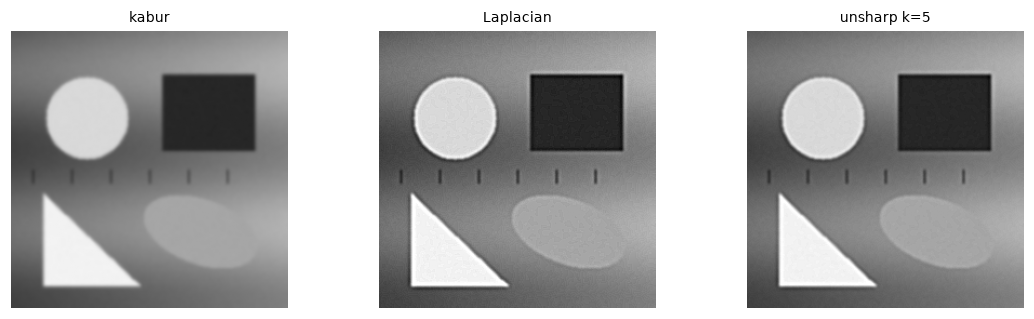

In [13]:
# TODO 3.3 — Penajaman citra `kabur` (Gonzalez Eq. 3-54 dan 3-55/3-56).
# (a) Laplacian 8-tetangga [[1,1,1],[1,-8,1],[1,1,1]]; karena pusat negatif, g = f − ∇²f.
# (b) Unsharp masking / highboost: g = f + k·(f − f_kabur), f_kabur = GaussianBlur(f, 5×5, σ=1,0), k ∈ {0,5; 1; 2,5; 5; 8; 12}.
# Untuk setiap hasil: PSNR terhadap `bersih` dan persentase piksel yang terpotong (<0 atau >255) SEBELUM clip.
# PENTING: kerjakan dalam float64, baru clip dan ubah ke uint8 di akhir.
f = kabur.astype(np.float64)

kernel_lap = np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]], float)
lap = cv2.filter2D(f, cv2.CV_64F, kernel_lap, borderType=cv2.BORDER_REPLICATE)
g_lap = f - lap
pct_lap = np.mean((g_lap < 0) | (g_lap > 255)) * 100
g_lap_u = np.clip(bulat(g_lap), 0, 255).astype(np.uint8)
print(f'Laplacian 8-tetangga: PSNR {psnr(bersih, g_lap_u):.4f} dB, terpotong {pct_lap:.3f}%')

f_kabur = cv2.GaussianBlur(f, (5, 5), 1.0)
hasil_unsharp = {}
print(f'{"k":>4s} {"PSNR (dB)":>10s} {"terpotong":>12s}')
for k in [0.5, 1, 2.5, 5, 8, 12]:
    g = f + k * (f - f_kabur)
    pct = np.mean((g < 0) | (g > 255)) * 100
    gu = np.clip(bulat(g), 0, 255).astype(np.uint8)
    hasil_unsharp[k] = gu
    print(f'{k:4.1f} {psnr(bersih, gu):10.4f} {pct:11.3f}%')

tampil([kabur, g_lap_u, hasil_unsharp[5]], ['kabur', 'Laplacian', 'unsharp k=5'], kolom=3)


In [14]:
# TODO 3.4 — Gradien Sobel (Gonzalez Eq. 3-62/3-63). Pada jendela z berikut, hitung tangan g_x dan g_y versi Gonzalez
# (x = arah BARIS), lalu cocokkan dengan cv2.Sobel. Perhatikan: pada OpenCV dx=1 berarti turunan arah KOLOM.
z = np.array([[30, 32, 120], [28, 35, 125], [31, 30, 130]], float)
# Jawaban tangan: g_x(Gonzalez) = 7, g_y(Gonzalez) = 383

gx_g = (z[2, 0] + 2*z[2, 1] + z[2, 2]) - (z[0, 0] + 2*z[0, 1] + z[0, 2])
gy_g = (z[0, 2] + 2*z[1, 2] + z[2, 2]) - (z[0, 0] + 2*z[1, 0] + z[2, 0])
print(f'Gonzalez: g_x (arah baris) = {gx_g:g}, g_y (arah kolom) = {gy_g:g}')

dx = cv2.Sobel(z, cv2.CV_64F, 1, 0, ksize=3)[1, 1]
dy = cv2.Sobel(z, cv2.CV_64F, 0, 1, ksize=3)[1, 1]
print(f'OpenCV  : dx=1 (arah kolom) = {dx:g}, dy=1 (arah baris) = {dy:g}')
print('Cocok: dx = g_y(Gonzalez) dan dy = g_x(Gonzalez)')


Gonzalez: g_x (arah baris) = 7, g_y (arah kolom) = 383
OpenCV  : dx=1 (arah kolom) = 383, dy=1 (arah baris) = 7
Cocok: dx = g_y(Gonzalez) dan dy = g_x(Gonzalez)


**Analisis 3.2.** (a) Mengapa $g = f - \nabla^2 f$ dan bukan $f + \nabla^2 f$ untuk kernel yang Anda pakai? (b) Tetapkan nilai $k$ unsharp masking untuk citra ini dengan dua angka sekaligus (PSNR dan persentase terpotong). (c) Mengapa menjalankan penajaman pada `berderau` tanpa penghalusan lebih dulu adalah gagasan buruk?

*Jawaban Anda:*

**(a)** Kernel Laplacian yang saya pakai berpusat −8, sehingga ∇²f = (jumlah 8 tetangga) − 8f. Untuk menajamkan, kita ingin mempertahankan f dan menambahkan komponen tepi dengan tanda yang benar, sehingga dipakai g = f − ∇²f = 9f − (jumlah 8 tetangga). Jika dipakai f + ∇²f, tanda tepi terbalik dan hasilnya cenderung mengabur atau mengganti f dengan rerata tetangga.

**(b)** Saya memilih **k = 5**: PSNR tertinggi 31,2552 dB dengan 0,485% piksel terpotong. Nilai k = 8 menurunkan PSNR ke 30,1342 dB dan menaikkan piksel terpotong menjadi 1,086%; k = 2,5 memberi 30,9323 dB dengan hanya 0,005% terpotong tetapi penajamannya lebih lemah. Sebagai pembanding, Laplacian murni memberi 30,6291 dB dengan 0,885% terpotong.

**(c)** Menajamkan `berderau` tanpa penghalusan lebih dulu adalah gagasan buruk karena operator penajaman (Laplacian/unsharp) bersifat high-pass: derau Gaussian dan terutama bintik garam–merica juga berfrekuensi tinggi, sehingga ikut diperkuat, SNR turun, dan muncul artefak bintik serta tepi palsu. Derau harus diredam (misalnya dengan median) sebelum penajaman.


## Bagian 4 &mdash; Studi kasus mini: citra perairan berkabut (15 menit)

Citra `perairan` meniru kamera pengawas pantai dalam kabut: kontras rendah dan berderau. Tujuan perbaikan: **memperjelas kapal terhadap laut** sebagai tahap awal sebelum deteksi. Ukur dengan rasio kontras terhadap derau:

$$\text{CNR} = \frac{|\mu_{kapal} - \mu_{laut}|}{\sigma_{laut}}$$

Masker kebenaran dasar tersedia dari `masker_perairan()`. **Peringatan:** citra ini sintetis dan tidak boleh dipakai untuk menyimpulkan kinerja pada citra kamera atau satelit sungguhan.

CNR asli: 3.2478
Alur                                   CNR |mu_kapal-mu_laut|  sigma_laut
A: CLAHE                            2.1351              38.32       17.95
B: median3 -> CLAHE                 2.8097              40.12       14.28
C: CLAHE -> median3                 2.6958              37.84       14.04
D: Gauss5 -> median3 -> CLAHE       3.5146              48.43       13.78


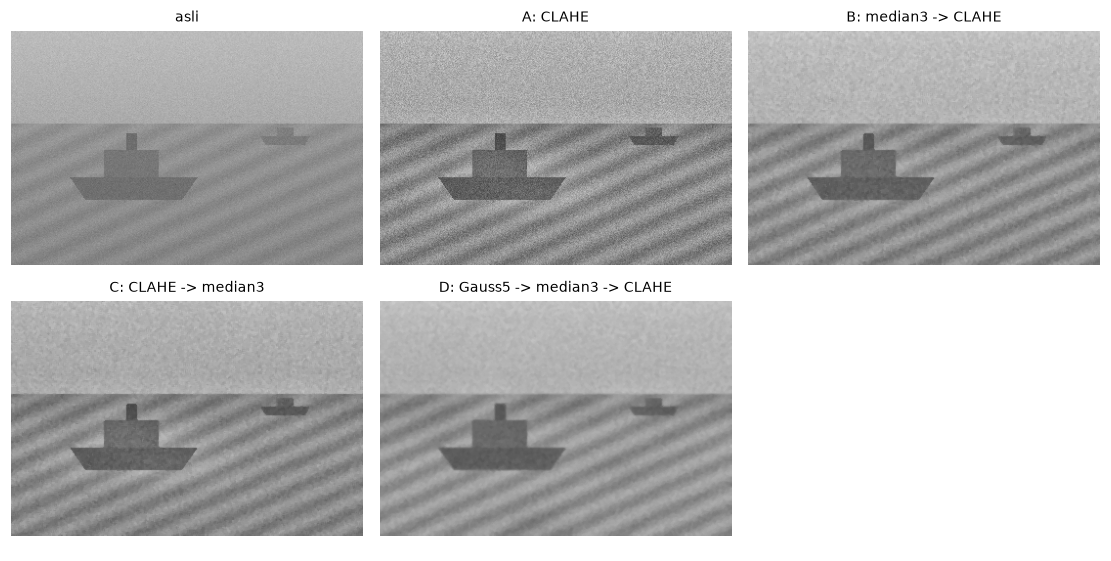


Setiap langkah alur D dijalankan sendiri-sendiri:
Gauss5               CNR  3.9307  |mu_kapal-mu_laut|  23.28  sigma_laut  5.92
median3              CNR  3.9560  |mu_kapal-mu_laut|  23.72  sigma_laut  6.00
CLAHE                CNR  2.1351  |mu_kapal-mu_laut|  38.32  sigma_laut 17.95
Gauss5 -> median3    CNR  4.0312  |mu_kapal-mu_laut|  23.17  sigma_laut  5.75


In [15]:
# TODO 4.1 — Lengkapi fungsi cnr, lalu bandingkan minimal empat alur:
#   A: CLAHE saja (clip 2, ubin 8×8)      B: median 3×3 lalu CLAHE
#   C: CLAHE lalu median 3×3              D: rancangan Anda sendiri (maks. 3 langkah)
kapal, laut = masker_perairan()
def cnr(im):
    return abs(im[kapal].mean() - im[laut].mean()) / im[laut].std()

def clahe2(im, clip=2.0):
    return cv2.createCLAHE(clipLimit=clip, tileGridSize=(8, 8)).apply(im)

alur = {
    'A: CLAHE': clahe2(perairan),
    'B: median3 -> CLAHE': clahe2(cv2.medianBlur(perairan, 3)),
    'C: CLAHE -> median3': cv2.medianBlur(clahe2(perairan), 3),
    'D: Gauss5 -> median3 -> CLAHE': clahe2(cv2.medianBlur(cv2.GaussianBlur(perairan, (5, 5), 0.8), 3)),
}

print(f'CNR asli: {cnr(perairan):.4f}')
print(f'{"Alur":34s} {"CNR":>7s} {"|mu_kapal-mu_laut|":>18s} {"sigma_laut":>11s}')
for nama, im in alur.items():
    print(f'{nama:34s} {cnr(im):7.4f} {abs(im[kapal].mean() - im[laut].mean()):18.2f} {im[laut].std():11.2f}')

tampil([perairan] + list(alur.values()), ['asli'] + list(alur.keys()), kolom=3, tinggi=2.6)

print('\nSetiap langkah alur D dijalankan sendiri-sendiri:')
langkah = {
    'Gauss5': cv2.GaussianBlur(perairan, (5, 5), 0.8),
    'median3': cv2.medianBlur(perairan, 3),
    'CLAHE': clahe2(perairan),
    'Gauss5 -> median3': cv2.medianBlur(cv2.GaussianBlur(perairan, (5, 5), 0.8), 3),
}
for nama, im in langkah.items():
    print(f'{nama:20s} CNR {cnr(im):7.4f}  |mu_kapal-mu_laut| {abs(im[kapal].mean() - im[laut].mean()):6.2f}  sigma_laut {im[laut].std():5.2f}')


**Analisis 4.** (a) Alur mana yang Anda pilih dan berapa CNR-nya? (b) Apakah urutan B dan C memberi angka yang sama? Jelaskan penyebabnya. (c) Mengapa HE global atau CLAHE saja bisa menaikkan beda rerata tetapi tidak selalu menaikkan CNR? (d) Bagian mana dari alur terbaik Anda yang sesungguhnya menaikkan CNR? Buktikan dengan menjalankan setiap langkahnya **sendiri-sendiri**. (e) Satu kalimat: apa yang **tidak** dapat Anda klaim dari percobaan ini tentang deteksi kapal sungguhan?

*Jawaban Anda:*

**(a)** Saya memilih alur **D: Gaussian 5×5 σ=0,8 → median 3×3 → CLAHE clip 2**, dengan CNR **3,5146**, tertinggi di antara empat alur yang diuji. Angka pembanding: asli 3,2478; A (CLAHE saja) 2,1351; B (median 3×3 → CLAHE) 2,8097; C (CLAHE → median 3×3) 2,6958.

**(b)** B dan C tidak memberi angka yang sama: B = 2,8097 dan C = 2,6958 (selisih 0,1139). Kedua operasi tidak komutatif. Pada B, median mengubah histogram lokal lebih dulu, sehingga CLAHE mengekualisasi histogram yang sudah dihaluskan. Pada C, CLAHE menaikkan kontras lokal (termasuk derau) lebih dulu, lalu median menghaluskan hasil ekualisasi tersebut; urutan yang berbeda menghasilkan distribusi lokal dan interpolasi antar-ubin yang berbeda.

**(c)** HE/CLAHE dapat menaikkan |μ_kapal − μ_laut| tetapi tidak selalu menaikkan CNR karena CNR membagi beda rerata dengan σ_laut. Pada A, |μ_kapal − μ_laut| naik dari 24,02 menjadi 38,32, tetapi σ_laut naik dari 7,39 menjadi 17,95 (2,43 kali), sehingga CNR justru turun dari 3,2478 menjadi 2,1351. Dengan kata lain, ekualisasi lokal memperkuat tekstur laut/derau hampir sebesar atau lebih besar daripada memperkuat beda kapal–laut.

**(d)** Pada alur D, kenaikan CNR sesungguhnya berasal dari dua tahap penghalusan: Gaussian 5×5 sendiri CNR 3,9307, median 3×3 sendiri 3,9560, dan gabungannya 4,0312, semuanya di atas CNR asli 3,2478. Tahap CLAHE justru menurunkan CNR dari 4,0312 menjadi 3,5146 karena σ_laut naik dari 5,75 menjadi 13,78 meskipun beda rerata naik dari 23,17 menjadi 48,43. Jadi CLAHE di sini berperan menaikkan kontras lokal secara visual, bukan menaikkan CNR; bila CNR satu-satunya kriteria, tahap CLAHE sebaiknya dihilangkan.

**(e)** Dari percobaan ini saya tidak dapat mengklaim apa pun tentang kinerja deteksi kapal pada citra kamera atau satelit sungguhan, karena citra yang dipakai sintetis dan CNR hanyalah proksi, bukan ukuran akurasi deteksi.


---
## Bagian 5 &mdash; Daftar periksa sebelum mengumpulkan (10 menit)

- [ ] Uji cepat TODO 1.1 mencetak `True` semua
- [ ] Pemetaan contoh 8 aras = `[1 3 5 6 6 7 7 7]` dan spesifikasi = `[2 3 5 6 6 7 7 7]`
- [ ] `lut_he_cdfmin` menghasilkan **0 piksel berbeda** dari `cv2.equalizeHist` pada kedua citra
- [ ] Korelasi buatan sendiri cocok dengan `cv2.filter2D` (selisih < 1e-9)
- [ ] Setiap blok Analisis memuat angka dari keluaran Anda sendiri
- [x] Penggunaan alat bantu AI (bila ada) dicantumkan: opencode, lihat catatan di akhir notebook
- [ ] Berkas dinamai `PraktikumPCD_SubCPMK2_NIM_Nama.ipynb` dan sudah dijalankan penuh

---
## Catatan penggunaan alat bantu AI

- **Alat:** opencode (asisten AI berbasis model bahasa).
- **Bagian yang dibantu:** penulisan kode untuk TODO 1.1&ndash;4.1 dan penyusunan kalimat pada blok Analisis 1&ndash;4.
- **Cara memeriksa kebenaran:** seluruh notebook dijalankan ulang dari awal tanpa error; uji cepat TODO 1.1 mencetak `True` semua; pemetaan HE contoh `[1 3 5 6 6 7 7 7]`; pemetaan spesifikasi `[2 3 5 6 6 7 7 7]`; `lut_he_cdfmin` menghasilkan 0 piksel berbeda dari `cv2.equalizeHist` pada kedua citra; korelasi buatan sendiri cocok dengan `cv2.filter2D` (selisih 0,0); dan setiap angka pada blok Analisis diambil dari keluaran sel yang bersangkutan.
